In [58]:
# preprocessing the images to get the resolutions similar.
# images will not be saved on disk (unless done)

import os
from PIL import Image
import numpy as np

def resize_and_normalize_image(img_path, size=(128, 128)):
    with Image.open(img_path) as img:
        # Resize the image
        img = img.resize(size)
        
        # Normalize pixel values
        img_array = np.asarray(img) / 255.0
        return img_array

def process_images_in_directory(directory_path):
    processed_images = []
    for filename in os.listdir(directory_path):
        if filename.endswith(".jpg"):
            img_path = os.path.join(directory_path, filename)
            processed_img = resize_and_normalize_image(img_path)
            processed_images.append(processed_img)
    return processed_images

# Paths to your datasets
train_path = "/Users/arpanghosal/Work/Software_tutorials/gitprojects/untitled folder/images/train"
train_pot_path = os.path.join(train_path, "pot")
#test_pot_path = os.path.join(base_path, "pot/test pot")
train_tom_path = os.path.join(train_path, "tom")
#test_tom_path = os.path.join(base_path, "tom/test tom")

# Paths to your datasets
test_path = "/Users/arpanghosal/Work/Software_tutorials/gitprojects/untitled folder/images/test"
test_pot_path = os.path.join(test_path, "pot")
test_tom_path = os.path.join(test_path, "tom")

# Process images
train_pot_images = process_images_in_directory(train_pot_path)
test_pot_images = process_images_in_directory(test_pot_path)
train_tom_images = process_images_in_directory(train_tom_path)
test_tom_images = process_images_in_directory(test_tom_path)


In [43]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense


In [44]:
# describing a simple model with conv and pooling filters
# conv gives dot product of conv times the image pixels
# pooling takes the dot products to give one comprehensive picture

model = Sequential([
    Conv2D(16, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(2, activation='softmax')
])


In [45]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


In [46]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Define the path to the training directory
train_dir = "/Users/arpanghosal/Work/Software_tutorials/gitprojects/untitled folder/images/train"

# Initialize the training data generator
train_datagen = ImageDataGenerator(rescale=1./255)
train_generator = train_datagen.flow_from_directory(
        train_dir,
        target_size=(128, 128),
        batch_size=1,
        class_mode='binary')  # 'binary' if you have two classes, 'categorical' for more

# Fit the model
# Make sure to define and compile your model before this step
history = model.fit(
      train_generator,
      steps_per_epoch=2,  # This should be total_images/batch_size
      epochs=2,
      # Include validation_data if you have a validation generator
      verbose=2)


Found 8 images belonging to 2 classes.
Epoch 1/2
2/2 - 1s - loss: 16.5990 - accuracy: 0.0000e+00 - 853ms/epoch - 426ms/step
Epoch 2/2
2/2 - 0s - loss: 0.0011 - accuracy: 1.0000 - 137ms/epoch - 69ms/step


In [50]:
test_dir = "/Users/arpanghosal/Work/Software_tutorials/gitprojects/untitled folder/images/test"

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(128, 128),
    batch_size=1,  # Can be different from the training batch size
    class_mode='binary',
    shuffle=False)  # No need to shuffle the test data


Found 6 images belonging to 2 classes.


In [51]:
test_loss, test_accuracy = model.evaluate(test_generator)
print("Test accuracy:", test_accuracy)


6/6 [==============================] - 0s 22ms/step - loss: 1.8979 - accuracy: 0.6667
Test accuracy: 0.6666666865348816


In [38]:
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Function to load and preprocess an image
def load_and_preprocess_image(image_path):
    img = load_img(image_path, target_size=(128, 128))
    img = img_to_array(img)
    img = np.expand_dims(img, axis=0)
    img /= 255.0
    return img

# Paths to your test images
test_images_paths = '/Users/arpanghosal/Work/Software_tutorials/gitprojects/untitled folder/images/test'  # Fill this with the paths to your test images

# Predict each image
for image_path in test_images_paths:
    img = load_and_preprocess_image(image_path)
    prediction = model.predict(img)
    predicted_class = np.argmax(prediction, axis=1)

    # Print the prediction and actual class
    print(f"Image: {image_path}, Predicted class: {predicted_class}, Actual class: ...")

# Note: You need to fill in the actual class manually or load it if you have corresponding labels


IsADirectoryError: [Errno 21] Is a directory: '/'

KeyError: 'val_accuracy'

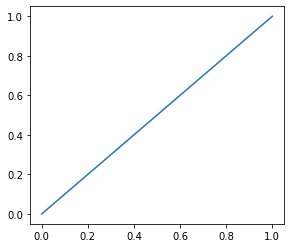

In [54]:
import matplotlib.pyplot as plt

# Plotting training and validation accuracy
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')  # Corrected key
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plotting training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')  # Corrected key
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()



In [55]:
# Stage - II

In [56]:
#pooling


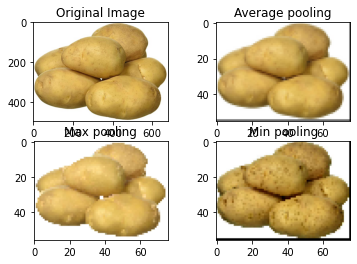

In [61]:
from skimage.measure import block_reduce
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.image import imread

img = imread('61yXL70-RaL._SX679_.jpg')


# Ensure img is float in the range [0, 1]
if img.dtype == np.uint8:
    img = img / 255.0

mean_pool=block_reduce(img, block_size=(9,9,1), func=np.mean)
max_pool=block_reduce(img, block_size=(9,9,1), func=np.max)
min_pool=block_reduce(img, block_size=(9,9,1), func=np.min)

plt.figure(1)
plt.subplot(221)
imgplot = plt.imshow(img)
plt.title('Original Image')

plt.subplot(222)
imgplot3 = plt.imshow(mean_pool)
plt.title('Average pooling')

plt.subplot(223)
imgplot1 = plt.imshow(max_pool)
plt.title('Max pooling')

plt.subplot(224)
imgplot1 = plt.imshow(min_pool)
plt.title('Min pooling')

plt.show()

1/1 [==============================] - 0s 49ms/step


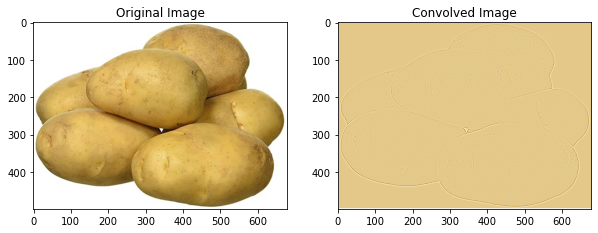

In [66]:
import tensorflow as tf
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.models import Sequential
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.image import imread

# Load and preprocess the image
img = imread('61yXL70-RaL._SX679_.jpg')
img = img / 255.0  # Normalize to [0, 1]
img = np.expand_dims(img, axis=0)  # Add batch dimension

# Define a simple convolutional layer
model = Sequential()
model.add(Conv2D(filters=1, kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=img.shape[1:]))


# Assuming the input image has 3 channels (RGB)
edge_detection_filter = np.array([[[[-1], [-1], [-1]], 
                                   [[-1], [-1], [-1]], 
                                   [[-1], [-1], [-1]]],
                                  [[[-1], [-1], [-1]], 
                                   [[8], [8], [8]], 
                                   [[-1], [-1], [-1]]],
                                  [[[-1], [-1], [-1]], 
                                   [[-1], [-1], [-1]], 
                                   [[-1], [-1], [-1]]]], dtype='float32')

# Reshape the filter to match the expected shape (3, 3, 3, 1)
edge_detection_filter = np.reshape(edge_detection_filter, (3, 3, 3, 1))

# Set the weights of the convolutional layer
model.layers[0].set_weights([edge_detection_filter, np.array([0])])  # Set filter weights and bias

# Apply the convolutional layer to the image
conv_img = model.predict(img)
conv_img = np.squeeze(conv_img)  # Remove batch dimension

# Display the original and convolved images
plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(np.squeeze(img), cmap='gray')
plt.title('Original Image')
plt.subplot(122)
plt.imshow(conv_img, cmap='BrBG')
plt.title('Convolved Image')
plt.show()


In [68]:
# Define a convolutional layer with multiple filters
model = Sequential()
model.add(Conv2D(filters=3, kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=img.shape[1:]))

# Define different filters (e.g., edge detection, sharpening)
filters = np.zeros((3, 3, 3, 3))  # Shape: (kernel_height, kernel_width, input_channels, output_channels)

# Update edge_detection_filter to match the shape (3, 3, 3)
edge_detection_filter_updated = np.array([[[-1, -1, -1], [-1, -1, -1], [-1, -1, -1]],
                                          [[-1, -1, -1], [ 8,  8,  8], [-1, -1, -1]],
                                          [[-1, -1, -1], [-1, -1, -1], [-1, -1, -1]]], dtype='float32')

# Assign the updated edge_detection_filter to the first filter slot
filters[:, :, :, 0] = edge_detection_filter_updated

# Define and assign the second filter (sharpening filter, for example)
sharpening_filter = np.array([[[ 0,  0,  0], [ 0,  1,  0], [ 0,  0,  0]],
                              [[ 0,  1,  0], [-5, -5, -5], [ 0,  1,  0]],
                              [[ 0,  0,  0], [ 0,  1,  0], [ 0,  0,  0]]], dtype='float32')
filters[:, :, :, 1] = sharpening_filter

# You can define a third filter or leave it as zeros

# Set the weights of the convolutional layer
model.layers[0].set_weights([filters, np.zeros(3)])  # Set filter weights and biases



1/1 [==============================] - 0s 88ms/step


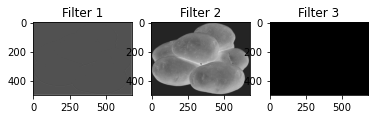

In [69]:
# Apply the convolutional layer to the image
feature_maps = model.predict(img)
for i in range(feature_maps.shape[-1]):  # Iterate over the filters
    plt.subplot(1, feature_maps.shape[-1], i+1)
    plt.imshow(feature_maps[0, :, :, i], cmap='gray')
    plt.title(f'Filter {i+1}')
plt.show()


1/1 [==============================] - 0s 94ms/step


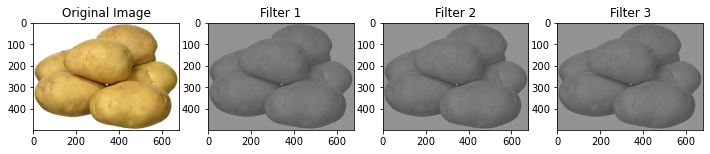

In [82]:
#Multi convoluted-filters approach:
"""
In this code:

    The image is loaded and normalized to have pixel values between 0 and 1.
    A CNN model with a single convolutional layer is created. This layer has 3 filters, 
    each designed to extract different features (edge detection, sharpening, and embossing).
    The filters are applied to image and resulting feature maps are visualized alongside the original image.
"""
import tensorflow as tf
from tensorflow.keras.layers import Conv2D

from tensorflow.keras.models import Sequential
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.image import imread

# Load the image
img_path = '61yXL70-RaL._SX679_.jpg'  # Path to your image
img = imread(img_path)

# Normalize the image
img_normalized = img / 255.0  # Convert pixel values from [0, 255] to [0, 1]

# Add a batch dimension
img_with_batch = np.expand_dims(img_normalized, axis=0)  # Add batch dimension for CNN

# Create a Sequential model with a single Conv2D layer
model = Sequential()
model.add(Conv2D(filters=3, kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=img_normalized.shape))

# Define filters
# Edge Detection Filter
edge_detection_filter = np.array([[-1, -1, -1], [-1, 10, -1], [-1, -1, -1]])

# Sharpening Filter
sharpening_filter = np.array([[0, -1, 0], [-1, 10, -1], [0, -1, 0]])

# Emboss Filter
emboss_filter = np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]])

# Initialize filters array with correct shape
filters = np.zeros((3, 3, 3, 3))  # (kernel_height, kernel_width, input_channels, output_channels)

# Assign filters to each channel
for i in range(3):
    filters[:, :, 0, i] = edge_detection_filter
    filters[:, :, 1, i] = sharpening_filter
    filters[:, :, 2, i] = emboss_filter

# Set the filters in the model
model.layers[0].set_weights([filters, np.zeros(3)])  # 3 filters, hence 3 biases

# Apply the convolutional layer to the image
conv_img = model.predict(img_with_batch)

# Visualize the original and convolved images
plt.figure(figsize=(12, 6))
plt.subplot(141)
plt.imshow(img_normalized)
plt.title('Original Image')

# Plot each filter's output
for i in range(3):
    plt.subplot(1, 4, i + 2)
    plt.imshow(conv_img[0, :, :, i], cmap='gray')
    plt.title(f'Filter {i+1}')
plt.show()


1/1 [==============================] - 0s 73ms/step


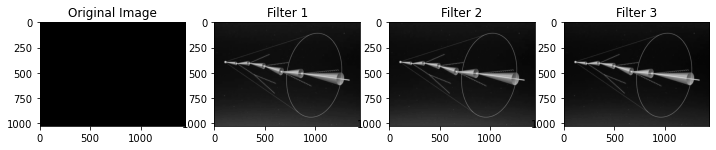

In [87]:
# Independent filters study:

import tensorflow as tf
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.models import Sequential
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.image import imread

# Load and preprocess the image
img_path = 'deadcone.png'  # Replace with your image path
img = imread(img_path)
if img.shape[-1] == 4:  # If the image has 4 channels
    img = img[:, :, :3]  # Keep only the first three channels

img_normalized = img / 255.0  # Normalize to [0, 1]
img_with_batch = np.expand_dims(img_normalized, axis=0)  # Add batch dimension

# Create a Sequential model with a single Conv2D layer
model = Sequential()
model.add(Conv2D(filters=3, kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=img_normalized.shape))

# Define three independent filters
filter1 = np.random.rand(3, 3, 3)  # Random filter for demonstration
filter2 = np.random.rand(3, 3, 3)  # Another random filter
filter3 = np.random.rand(3, 3, 3)  # Yet another random filter

# Initialize filters array with correct shape
filters = np.zeros((3, 3, 3, 3))  # (kernel_height, kernel_width, input_channels, output_channels)

# Assign the independent filters
filters[:, :, :, 0] = filter1  # First filter
filters[:, :, :, 1] = filter2  # Second filter
filters[:, :, :, 2] = filter3  # Third filter

# Set the filters in the model
model.layers[0].set_weights([filters, np.zeros(3)])  # 3 filters, hence 3 biases

# Apply the convolutional layer to the image
conv_img = model.predict(img_with_batch)

# Visualize the original and convolved images
plt.figure(figsize=(12, 6))
plt.subplot(141)
plt.imshow(img_normalized)
plt.title('Original Image')

# Plot each filter's output
for i in range(3):
    plt.subplot(1, 4, i + 2)
    plt.imshow(conv_img[0, :, :, i], cmap='gray')
    plt.title(f'Filter {i+1}')
plt.show()


1/1 [==============================] - 0s 52ms/step


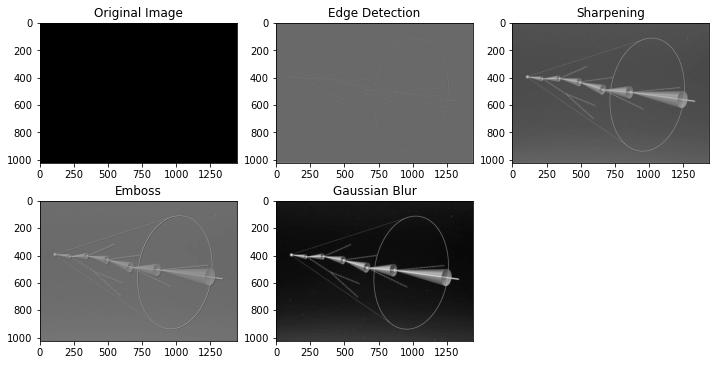

In [90]:
import tensorflow as tf
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.models import Sequential
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.image import imread

# Load and preprocess the image
img_path = 'deadcone.png'  # Replace with your image path
img = imread(img_path)
img_normalized = img / 255.0  # Normalize to [0, 1]
if img_normalized.shape[-1] == 4:  # Check if the image has 4 channels (RGBA)
    img_normalized = img_normalized[:, :, :3]  # Keep only RGB channels
img_with_batch = np.expand_dims(img_normalized, axis=0)  # Add batch dimension

# Define specific filters
# Edge Detection Filter
edge_detection_filter = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]])

# Sharpening Filter
sharpening_filter = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])

# Emboss Filter
emboss_filter = np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]])

# Gaussian Blur Filter
gaussian_blur_filter = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16

# Apply each filter individually
filters = [edge_detection_filter, sharpening_filter, emboss_filter, gaussian_blur_filter]
titles = ['Edge Detection', 'Sharpening', 'Emboss', 'Gaussian Blur']

# Display original and filtered images
plt.figure(figsize=(12, 6))
plt.subplot(2, 3, 1)
plt.imshow(img_normalized)
plt.title('Original Image')

# Apply and display each filter
for i, (filter, title) in enumerate(zip(filters, titles), start=1):
    model = Sequential()
    model.add(Conv2D(filters=1, kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=img_normalized.shape))
    
    # Expand dimensions of filter to match Conv2D weights shape
    filter_expanded = np.expand_dims(np.expand_dims(filter, axis=-1), axis=-1)
    filter_expanded = np.repeat(filter_expanded, img_normalized.shape[-1], axis=2)  # Repeat for each input channel

    model.layers[0].set_weights([filter_expanded, np.array([0])])
    conv_img = model.predict(img_with_batch)

    plt.subplot(2, 3, i + 1)
    plt.imshow(np.squeeze(conv_img), cmap='gray')
    plt.title(title)

plt.show()
